# MAGPI 1D Aperture Spectra Product Viewer — H$\alpha$ & H$\beta$ S/N Selection Cut Example

This notebook is intended to act as a starting point for working with the MAGPI 'onedspec Emission Line Products' located in MAGPI_ELDR_onedspec_products.zip. For details on the FITS table, please refer to `README_MAGPI_ELDR_onedspec_products.txt`, which is inside the zip directory and Battisti et al. (2026).

The onedspec products can serve as a useful starting point to select a galaxy sample for a specific analysis goal. For example, this script selects galaxies with S/N $\geq 3$ in **both** H$\alpha$ and H$\beta$ measured in the **undilated ProFound mask aperture**, which can be used to study dust attenuation via the Balmer decrement (H$\alpha$/H$\beta$), and then plots their redshift ($z_{spec}$) distribution.

Flux units of the lines are $10^{-20}\,\mathrm{erg\,s^{-1}\,cm^{-2}}$


In [20]:
# ================== Imports ==================
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table

plt.rcParams["figure.dpi"] = 100


## Configuration

In [4]:
# ================== User configuration ==================
FITS_PATH = "MAGPI_ELDR_onedspec_products.fits"   # path to the onedspec table

SN_CUT_HA = 3.0     # minimum S/N required in Ha
SN_CUT_HB = 3.0     # minimum S/N required in Hb
APERTURE = "undilated"   # 'dilated' or 'undilated' -- which MASK_APER entry to use

SAVE_FIG = False
OUTPUT_DIR = "."
FIG_FORMAT = "png"
FIG_DPI = 150


## Load the table

In [7]:
hdul = fits.open(FITS_PATH)
tab = Table(hdul[1].data)
print(f"Loaded {len(tab)} rows from {FITS_PATH}")
tab[:5]


Loaded 2607 rows from /Users/00115191/Research_data/MAGPI/GIST_results_v2.2.1/MAGPI_ELDR_onedspec_products/MAGPI_ELDR_onedspec_products.fits


MAGPI_ID,Z_SPEC,REDUCED_CHI2_FIXED_APER,REDUCED_CHI2_RE_APER,REDUCED_CHI2_MASK_APER,D4000_OBS_FIXED_APER,D4000_OBS_RE_APER,D4000_OBS_MASK_APER,D4000_OBS_ERR_FIXED_APER,D4000_OBS_ERR_RE_APER,D4000_OBS_ERR_MASK_APER,D4000_FIT_FIXED_APER,D4000_FIT_RE_APER,D4000_FIT_MASK_APER,DN4000_OBS_FIXED_APER,DN4000_OBS_RE_APER,DN4000_OBS_MASK_APER,DN4000_OBS_ERR_FIXED_APER,DN4000_OBS_ERR_RE_APER,DN4000_OBS_ERR_MASK_APER,DN4000_FIT_FIXED_APER,DN4000_FIT_RE_APER,DN4000_FIT_MASK_APER,EBV_GAS_FIXED_APER,EBV_GAS_RE_APER,EBV_GAS_MASK_APER,EBVERR_GAS_FIXED_APER,EBVERR_GAS_RE_APER,EBVERR_GAS_MASK_APER,V_GAS_FIXED_APER,V_GAS_RE_APER,V_GAS_MASK_APER,VERR_GAS_FIXED_APER,VERR_GAS_RE_APER,VERR_GAS_MASK_APER,SIGMA_GAS_FIXED_APER,SIGMA_GAS_RE_APER,SIGMA_GAS_MASK_APER,SIGMAERR_GAS_FIXED_APER,SIGMAERR_GAS_RE_APER,SIGMAERR_GAS_MASK_APER,OII_TOT_F_FIXED_APER,OII_TOT_F_RE_APER,OII_TOT_F_MASK_APER,OII_TOT_FERR_FIXED_APER,OII_TOT_FERR_RE_APER,OII_TOT_FERR_MASK_APER,NEIII_3870_F_FIXED_APER,NEIII_3870_F_RE_APER,NEIII_3870_F_MASK_APER,NEIII_3870_FERR_FIXED_APER,NEIII_3870_FERR_RE_APER,NEIII_3870_FERR_MASK_APER,H5_F_FIXED_APER,H5_F_RE_APER,H5_F_MASK_APER,H5_FERR_FIXED_APER,H5_FERR_RE_APER,H5_FERR_MASK_APER,NEIII_3969_F_FIXED_APER,NEIII_3969_F_RE_APER,NEIII_3969_F_MASK_APER,NEIII_3969_FERR_FIXED_APER,NEIII_3969_FERR_RE_APER,NEIII_3969_FERR_MASK_APER,HE_F_FIXED_APER,HE_F_RE_APER,HE_F_MASK_APER,HE_FERR_FIXED_APER,HE_FERR_RE_APER,HE_FERR_MASK_APER,HD_F_FIXED_APER,HD_F_RE_APER,HD_F_MASK_APER,HD_FERR_FIXED_APER,HD_FERR_RE_APER,HD_FERR_MASK_APER,HG_F_FIXED_APER,HG_F_RE_APER,HG_F_MASK_APER,HG_FERR_FIXED_APER,HG_FERR_RE_APER,HG_FERR_MASK_APER,OIII_4364_F_FIXED_APER,OIII_4364_F_RE_APER,OIII_4364_F_MASK_APER,OIII_4364_FERR_FIXED_APER,OIII_4364_FERR_RE_APER,OIII_4364_FERR_MASK_APER,HEII_4687_F_FIXED_APER,HEII_4687_F_RE_APER,HEII_4687_F_MASK_APER,HEII_4687_FERR_FIXED_APER,HEII_4687_FERR_RE_APER,HEII_4687_FERR_MASK_APER,ARIV_4713_F_FIXED_APER,ARIV_4713_F_RE_APER,ARIV_4713_F_MASK_APER,ARIV_4713_FERR_FIXED_APER,ARIV_4713_FERR_RE_APER,ARIV_4713_FERR_MASK_APER,ARIV_4741_F_FIXED_APER,ARIV_4741_F_RE_APER,ARIV_4741_F_MASK_APER,ARIV_4741_FERR_FIXED_APER,ARIV_4741_FERR_RE_APER,ARIV_4741_FERR_MASK_APER,HB_F_FIXED_APER,HB_F_RE_APER,HB_F_MASK_APER,HB_FERR_FIXED_APER,HB_FERR_RE_APER,HB_FERR_MASK_APER,OIII_5008_F_FIXED_APER,OIII_5008_F_RE_APER,OIII_5008_F_MASK_APER,OIII_5008_FERR_FIXED_APER,OIII_5008_FERR_RE_APER,OIII_5008_FERR_MASK_APER,NI_5199_F_FIXED_APER,NI_5199_F_RE_APER,NI_5199_F_MASK_APER,NI_5199_FERR_FIXED_APER,NI_5199_FERR_RE_APER,NI_5199_FERR_MASK_APER,NI_5202_F_FIXED_APER,NI_5202_F_RE_APER,NI_5202_F_MASK_APER,NI_5202_FERR_FIXED_APER,NI_5202_FERR_RE_APER,NI_5202_FERR_MASK_APER,HEI_5877_F_FIXED_APER,HEI_5877_F_RE_APER,HEI_5877_F_MASK_APER,HEI_5877_FERR_FIXED_APER,HEI_5877_FERR_RE_APER,HEI_5877_FERR_MASK_APER,OI_6302_F_FIXED_APER,OI_6302_F_RE_APER,OI_6302_F_MASK_APER,OI_6302_FERR_FIXED_APER,OI_6302_FERR_RE_APER,OI_6302_FERR_MASK_APER,HA_F_FIXED_APER,HA_F_RE_APER,HA_F_MASK_APER,HA_FERR_FIXED_APER,HA_FERR_RE_APER,HA_FERR_MASK_APER,NII_6585_F_FIXED_APER,NII_6585_F_RE_APER,NII_6585_F_MASK_APER,NII_6585_FERR_FIXED_APER,NII_6585_FERR_RE_APER,NII_6585_FERR_MASK_APER,SII_6718_F_FIXED_APER,SII_6718_F_RE_APER,SII_6718_F_MASK_APER,SII_6718_FERR_FIXED_APER,SII_6718_FERR_RE_APER,SII_6718_FERR_MASK_APER,SII_6733_F_FIXED_APER,SII_6733_F_RE_APER,SII_6733_F_MASK_APER,SII_6733_FERR_FIXED_APER,SII_6733_FERR_RE_APER,SII_6733_FERR_MASK_APER
str10,float32,float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32[4],float32[2],float32[13],float32

## Select the aperture and compute S/N

`*_MASK_APER` columns are shape `(N, 2)`, ordered `[dilated, undilated]`. 
Pull out the requested aperture column, then compute S/N for H$\alpha$ and H$\beta$.


In [14]:
aper_index = {"dilated": 0, "undilated": 1}[APERTURE]

def mask_aper_col(name, index=aper_index):
    '''Return the 1D array for a given *_MASK_APER column at the chosen aperture.'''
    return np.asarray(tab[name])[:, index]

Ha_F = mask_aper_col("HA_F_MASK_APER")
Ha_FERR = mask_aper_col("HA_FERR_MASK_APER")
Hb_F = mask_aper_col("HB_F_MASK_APER")
Hb_FERR = mask_aper_col("HB_FERR_MASK_APER")
z_spec = np.asarray(tab["Z_SPEC"])
magpi_id = np.asarray(tab["MAGPI_ID"])

with np.errstate(divide="ignore", invalid="ignore"):
    Ha_SNR = Ha_F / Ha_FERR
    Hb_SNR = Hb_F / Hb_FERR

print(f"Aperture: {APERTURE}  (MASK_APER index {aper_index})")
print(f"Cases with finite Ha S/N: {np.isfinite(Ha_SNR).sum()} / {len(tab)}")
print(f"Cases with finite Hb S/N: {np.isfinite(Hb_SNR).sum()} / {len(tab)}")


Aperture: undilated  (MASK_APER index 1)
Cases with finite Ha S/N: 797 / 2607
Cases with finite Hb S/N: 1764 / 2607


## Apply the S/N selection

In [30]:
good = np.isfinite(Ha_SNR) & np.isfinite(Hb_SNR) & \
       (Ha_SNR >= SN_CUT_HA) & (Hb_SNR >= SN_CUT_HB)

n_good = good.sum()
print(f"{n_good} / {len(tab)} sources pass S/N(Ha) >= {SN_CUT_HA} "
      f"and S/N(Hb) >= {SN_CUT_HB} in the {APERTURE} mask aperture.")

z_good = z_spec[good]
ids_good = magpi_id[good]

selected = Table({
    "MAGPI_ID": ids_good,
    "Z_SPEC": z_good,
    "Ha_SNR": Ha_SNR[good],
    "Hb_SNR": Hb_SNR[good],
})
selected.sort("Z_SPEC")
selected[:10]


501 / 2607 sources pass S/N(Ha) >= 3.0 and S/N(Hb) >= 3.0 in the undilated mask aperture.


MAGPI_ID,Z_SPEC,Ha_SNR,Hb_SNR
str10,float32,float32,float32
2312150322,0.0642,44.040695,14.577051
1204355300,0.0778,50.959984,11.185561
1512281206,0.0823,118.08643,30.362133
1512211075,0.0825,21.800463,4.806832
2306319078,0.084,129.08354,54.02678
2307297145,0.0843,71.26323,17.62985
1514152197,0.0985,279.52792,66.98749
1535087185,0.0995,92.54174,27.204538
1535085195,0.0996,222.95886,125.69026


## Redshift distribution

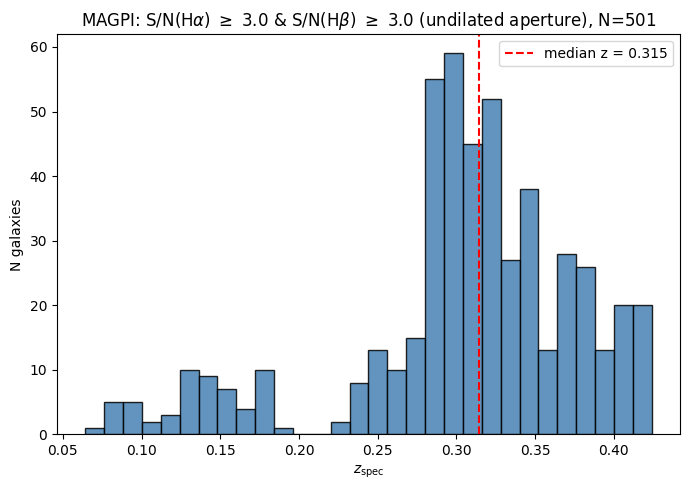

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'MAGPI: S/N(H$\\alpha$) $\\geq$ 3.0 & S/N(H$\\beta$) $\\geq$ 3.0 (undilated aperture), N=501'}, xlabel='$z_{\\rm spec}$', ylabel='N galaxies'>)

In [25]:
def plot_redshift_hist(z, bins=30, save=None, filename=None):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(z, bins=bins, color="steelblue", edgecolor="black", alpha=0.85)
    ax.set_xlabel(r"$z_{\rm spec}$")
    ax.set_ylabel("N galaxies")
    ax.set_title(
        rf"MAGPI: S/N(H$\alpha$) $\geq$ {SN_CUT_HA} & S/N(H$\beta$) $\geq$ {SN_CUT_HB} "
        f"({APERTURE} aperture), N={len(z)}"
    )
    ax.axvline(np.median(z), color="red", ls="--", lw=1.5,
               label=f"median z = {np.median(z):.3f}")
    ax.legend()
    fig.tight_layout()

    do_save = SAVE_FIG if save is None else save
    if do_save:
        if filename is None:
            filename = f"MAGPI_zspec_hist_SNge{SN_CUT_HA:.0f}_{APERTURE}.{FIG_FORMAT}"
        import os
        path = os.path.join(OUTPUT_DIR, filename)
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
        print(f"[saved] {path}")

    plt.show()
    return fig, ax


plot_redshift_hist(z_good, bins=30)


## Summary statistics

In [28]:
print(f"N selected      : {n_good}")
print(f"z range          : {z_good.min():.4f} -- {z_good.max():.4f}")
print(f"z median          : {np.median(z_good):.4f}")
print(f"z mean +/- std    : {np.mean(z_good):.4f} +/- {np.std(z_good):.4f}")


N selected      : 501
z range          : 0.0642 -- 0.4241
z median          : 0.3146
z mean +/- std    : 0.3053 +/- 0.0746


## Notes

- To change the S/N threshold or switch to the dilated-mask aperture, edit
  `SN_CUT_HA`, `SN_CUT_HB`, or `APERTURE` in the **Configuration** cell and
  re-run.
- The other aperture families (`*_FIXED_APER`, 13 fixed radii; `*_RE_APER`,
  4 $R_e$-based radii) follow the same column-indexing pattern and can be
  selected the same way by pulling the relevant index out of those columns
  instead of `*_MASK_APER`.
- `selected` (an `astropy.table.Table`) holds the MAGPI IDs, redshifts, and
  S/N values of every source that passed the cut, for further use (e.g.
  cross-matching against the 2D map products).
